# Explore Spider dataset

Schema, query, and length exploration for the Spider Text-to-SQL dataset, over
the raw download in `data/raw/` and the instruction-formatted splits this
project produces in `data/processed/` (see `reports/data_preparation.md` for
how those splits were built).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import json
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

from text2sql.data.schema_utils import load_tables, schema_to_ddl, build_schema_index
from text2sql.utils.config import load_config, resolve_path

%matplotlib inline
plt.rcParams["figure.figsize"] = (7, 4)

data_config = load_config(PROJECT_ROOT / "configs" / "data_config.yaml")
raw_dir = resolve_path(data_config["raw_dir"])
processed_dir = resolve_path(data_config["processed_dir"])
raw_dir, processed_dir

Matplotlib is building the font cache; this may take a moment.


(WindowsPath('C:/Users/PC/Downloads/text2sql-qlora/data/raw'),
 WindowsPath('C:/Users/PC/Downloads/text2sql-qlora/data/processed'))

## Dataset sizes

Raw question/SQL pairs per split, and how many distinct databases each draws from.

In [2]:
def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

train_spider = load_json(raw_dir / "train_spider.json")
train_others = load_json(raw_dir / "train_others.json")
dev_raw = load_json(raw_dir / "dev.json")
test_raw = load_json(raw_dir / "test.json")

sizes = pd.DataFrame([
    {"split": "train_spider.json", "examples": len(train_spider), "distinct_dbs": len({r["db_id"] for r in train_spider})},
    {"split": "train_others.json", "examples": len(train_others), "distinct_dbs": len({r["db_id"] for r in train_others})},
    {"split": "dev.json", "examples": len(dev_raw), "distinct_dbs": len({r["db_id"] for r in dev_raw})},
    {"split": "test.json", "examples": len(test_raw), "distinct_dbs": len({r["db_id"] for r in test_raw})},
])
sizes

,split,examples,distinct_dbs
0,train_spider.json,7000,140
1,train_others.json,1659,6
2,dev.json,1034,20
3,test.json,2147,40


In [3]:
train_dbs = {r["db_id"] for r in train_spider} | {r["db_id"] for r in train_others}
dev_dbs = {r["db_id"] for r in dev_raw}
test_dbs = {r["db_id"] for r in test_raw}

print(f"train+dev distinct dbs: {len(train_dbs | dev_dbs)}")
print(f"test dbs not in train/dev: {len(test_dbs - (train_dbs | dev_dbs))} / {len(test_dbs)}")
print("-> test is a genuinely held-out, cross-domain split (see reports/data_preparation.md)")

train+dev distinct dbs: 166
test dbs not in train/dev: 40 / 40
-> test is a genuinely held-out, cross-domain split (see reports/data_preparation.md)


## Schema shape

`test_tables.json` turns out to be a superset covering all 206 databases
(the 166 shared with train/dev, plus the 40 test-only ones) -- see
`reports/data_preparation.md` -- so it's used here as the single source for
corpus-wide schema stats.

In [4]:
all_tables = load_json(raw_dir / "test_tables.json")

rows = []
for t in all_tables:
    n_tables = len(t["table_names_original"])
    n_columns = len(t["column_names_original"]) - 1  # -1 for the "*" placeholder
    rows.append({"db_id": t["db_id"], "n_tables": n_tables, "n_columns": n_columns})

schema_df = pd.DataFrame(rows)
schema_df[["n_tables", "n_columns"]].describe()

,n_tables,n_columns
count,206.000000,206.000000
mean,5.126214,25.669903
std,3.706763,28.304232
min,2.000000,5.000000
25%,3.000000,13.000000
50%,4.000000,19.000000
75%,6.750000,28.000000
max,26.000000,352.000000


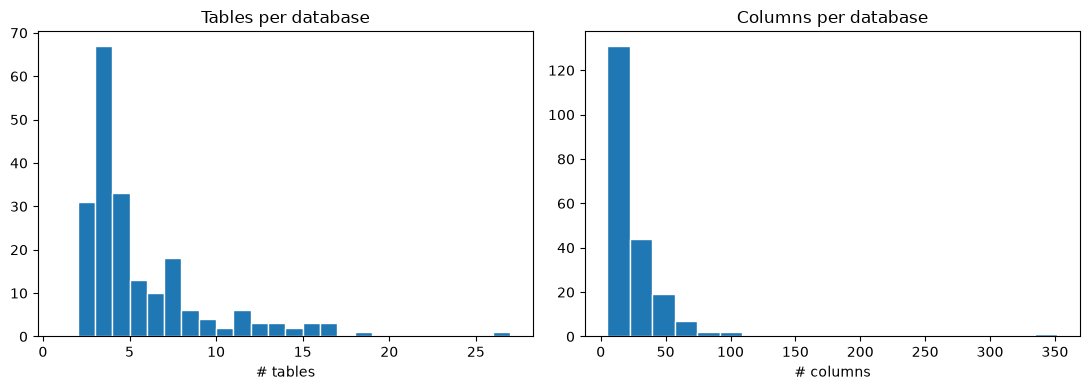

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(schema_df["n_tables"], bins=range(1, schema_df["n_tables"].max() + 2), edgecolor="white")
axes[0].set_title("Tables per database")
axes[0].set_xlabel("# tables")
axes[1].hist(schema_df["n_columns"], bins=20, edgecolor="white")
axes[1].set_title("Columns per database")
axes[1].set_xlabel("# columns")
plt.tight_layout()
plt.show()

## Example rendered schema (DDL)

What `schema_utils.schema_to_ddl` actually feeds into the prompt, for one training database.

In [6]:
trainval_tables = load_tables(raw_dir / "tables.json")
example_db = "department_management"
print(schema_to_ddl(trainval_tables[example_db]))

CREATE TABLE "department" (
  "Department_ID" NUMBER PRIMARY KEY,
  "Name" TEXT,
  "Creation" TEXT,
  "Ranking" NUMBER,
  "Budget_in_Billions" NUMBER,
  "Num_Employees" NUMBER
);

CREATE TABLE "head" (
  "head_ID" NUMBER PRIMARY KEY,
  "name" TEXT,
  "born_state" TEXT,
  "age" NUMBER
);

CREATE TABLE "management" (
  "department_ID" NUMBER PRIMARY KEY,
  "head_ID" NUMBER,
  "temporary_acting" TEXT,
  FOREIGN KEY ("department_ID") REFERENCES "department"("Department_ID"),
  FOREIGN KEY ("head_ID") REFERENCES "head"("head_ID")
);


## Query complexity

Heuristic categories mirroring `configs/eval_config.yaml`'s
`error_analysis.categories: [select, join, subquery, aggregation]` -- a query
can match more than one (e.g. a join with an aggregate), so these are
independent "contains X" flags, not a single exclusive label.

In [7]:
AGG_FUNCS = re.compile(r"\b(COUNT|AVG|SUM|MAX|MIN)\s*\(", re.IGNORECASE)

def classify(query: str) -> dict:
    q = query.upper()
    return {
        "join": " JOIN " in q,
        "subquery": q.count("SELECT") > 1,
        "aggregation": bool(AGG_FUNCS.search(query)),
        "group_by": "GROUP BY" in q,
    }

train_all = train_spider + train_others
flags_df = pd.DataFrame([classify(r["query"]) for r in train_all])
complexity = flags_df.mean().mul(100).round(1).rename("% of train queries")
complexity

join           44.0
subquery       15.6
aggregation    46.0
group_by       22.6
Name: % of train queries, dtype: float64

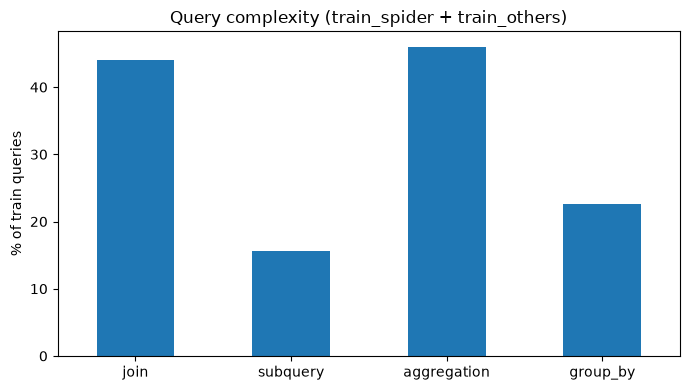

In [8]:
complexity.plot(kind="bar", ylabel="% of train queries", title="Query complexity (train_spider + train_others)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Sequence length vs. max_seq_length

Distribution over the already-preprocessed, already-filtered
`data/processed/*.json` (see `reports/data_preparation.md` for how the
1024 -> 1536 token budget decision was made, and the 84 train examples that
were dropped for exceeding it).

In [9]:
from transformers import AutoTokenizer

train_config = load_config(PROJECT_ROOT / "configs" / "train_config.yaml")
tokenizer = AutoTokenizer.from_pretrained(train_config["base_model"])
max_seq_length = data_config["max_seq_length"]

lengths_by_split = {}
for split in ["train", "dev", "test"]:
    examples = load_json(resolve_path(data_config[f"{split}_file"]))
    lengths_by_split[split] = [len(tokenizer.apply_chat_template(ex["messages"], tokenize=True)) for ex in examples]

pd.DataFrame({split: pd.Series(lengths).describe() for split, lengths in lengths_by_split.items()})

C:\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,train,dev,test
count,8575.000000,1034.000000,2147.000000
mean,481.254577,385.048356,370.041453
std,250.906441,171.333796,195.461477
min,135.000000,184.000000,142.000000
25%,288.000000,271.000000,241.500000
50%,436.000000,334.500000,311.000000
75%,577.000000,415.750000,435.000000
max,1506.000000,903.000000,1058.000000


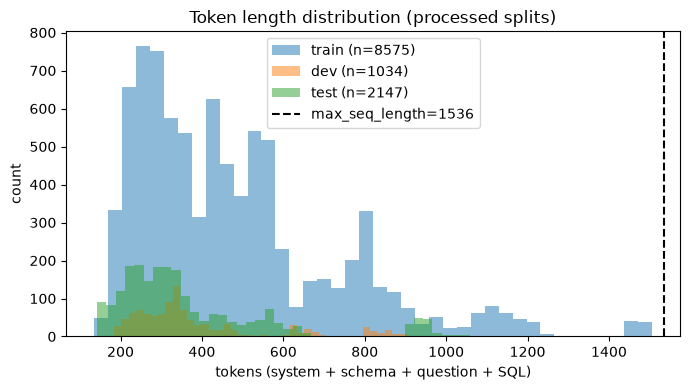

In [10]:
fig, ax = plt.subplots()
for split, lengths in lengths_by_split.items():
    ax.hist(lengths, bins=40, alpha=0.5, label=f"{split} (n={len(lengths)})")
ax.axvline(max_seq_length, color="black", linestyle="--", label=f"max_seq_length={max_seq_length}")
ax.set_xlabel("tokens (system + schema + question + SQL)")
ax.set_ylabel("count")
ax.legend()
ax.set_title("Token length distribution (processed splits)")
plt.tight_layout()
plt.show()

## Example instruction-formatted training record

What actually gets fed to the trainer for one example.

In [11]:
processed_train = load_json(resolve_path(data_config["train_file"]))
example = processed_train[0]
print("db_id:", example["db_id"], "| db_dir:", example["db_dir"])
print()
for m in example["messages"]:
    print(f"[{m['role']}]")
    print(m["content"])
    print()

db_id: department_management | db_dir: database

[system]
You are a SQL expert. Given a database schema and a question, write the SQLite query that answers the question.
Respond with the SQL query only -- no explanation, no markdown code fences.

[user]
### Schema:
CREATE TABLE "department" (
  "Department_ID" NUMBER PRIMARY KEY,
  "Name" TEXT,
  "Creation" TEXT,
  "Ranking" NUMBER,
  "Budget_in_Billions" NUMBER,
  "Num_Employees" NUMBER
);

CREATE TABLE "head" (
  "head_ID" NUMBER PRIMARY KEY,
  "name" TEXT,
  "born_state" TEXT,
  "age" NUMBER
);

CREATE TABLE "management" (
  "department_ID" NUMBER PRIMARY KEY,
  "head_ID" NUMBER,
  "temporary_acting" TEXT,
  FOREIGN KEY ("department_ID") REFERENCES "department"("Department_ID"),
  FOREIGN KEY ("head_ID") REFERENCES "head"("head_ID")
);

### Question:
How many heads of the departments are older than 56 ?

### SQL:

[assistant]
SELECT count(*) FROM head WHERE age  >  56



## Summary

- Spider ships a genuinely cross-domain test split: none of `test.json`'s 40
  databases appear in train/dev.
- Database schemas vary widely in size (see histograms above) -- this is
  most of why some examples' rendered DDL pushes past the token budget.
- Roughly a third to a half of train queries involve a join or an
  aggregate, per the heuristic classification above -- consistent with the
  README's claim that few-shot prompting alone tends to fail on these.
- `max_seq_length: 1536` (raised from an initial 1024) keeps 99%+ of
  examples intact; the small remainder is dropped rather than truncated, so
  no training example has a clipped SQL answer -- see
  `reports/data_preparation.md`.